# MINERÍA DE DATOS Y MODELIZACIÓN PREDICTIVA
# "Tarea de ACP + Clustering"

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import os
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA 
from sklearn.preprocessing import StandardScaler

# Más adelante hay librerías cargadas conforme se van utilizando

In [ ]:
os.chdir("/Desktop/Minería y modelización 3") 
from FuncionesMineria2 import (plot_varianza_explicada, plot_cos2_heatmap, plot_corr_cos, plot_cos2_bars,
                               plot_contribuciones_proporcionales, plot_pca_scatter, plot_pca_scatter_with_vectors,
                               plot_pca_scatter_with_categories)

### Carga del dataset  Palmer Penguins

In [192]:
df = sns.load_dataset("penguins")
print(df.shape)
df.head()

(344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [193]:
df.dtypes

species               object
island                object
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                   object
dtype: object

### Corrección de datos

In [194]:
# Análisis de valores perdidos

df.isna().sum()

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

In [195]:
# Antes de estandarizar los datos vamos a hacernos cargo de los datos missing, datos atípicos y la escala de las variables. 

# Vemos si hay muestras que puedan ser eliminadas
print(df.shape)
df.loc[df.isnull().sum(axis=1).sort_values(ascending=False).head(10).index]


(344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
324,Gentoo,Biscoe,47.3,13.8,216.0,4725.0,NaN
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN
286,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN
336,Gentoo,Biscoe,44.5,15.7,217.0,4875.0,NaN
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN
47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN


In [196]:
# Dos de las muestras presentan hasta 5 valores missing las eliminamos y nos quedamos con el resto.

df = df[df.isnull().mean(axis=1) <= 0.5]  # Eliminamos valores con más de 50% de missings.
print(df.shape)
print("Valores nulos restantes:", 
      df.isna().sum())
df.loc[df.isnull().sum(axis=1).sort_values(ascending=False).head(10).index]

(342, 7)
Valores nulos restantes: species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  9
dtype: int64


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN
286,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN
336,Gentoo,Biscoe,44.5,15.7,217.0,4875.0,NaN
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN
246,Gentoo,Biscoe,44.5,14.3,216.0,4100.0,NaN
324,Gentoo,Biscoe,47.3,13.8,216.0,4725.0,NaN
47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN
231,Gentoo,Biscoe,49.0,16.1,216.0,5550.0,Male


In [197]:
#    - Vemos que solo hay valores missing de la variable 'sex', siendo tan solo 9 valores vamos a imputarlos por el valor modal.
#    - Lo cierto es que de cara al PCA vamos tan solo a utilizar las variables continuas, 
# pero 'sex' podría ser útil de cara a detectar algún patrón posteriormente.  

df['sex'] = df['sex'].fillna(df['sex'].mode()[0])
print("Valores nulos restantes:", 
      df.isna().sum())
df.loc[df.isnull().sum(axis=1).sort_values(ascending=False).head(10).index]

Valores nulos restantes: species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
226,Gentoo,Biscoe,45.4,14.6,211.0,4800.0,Female
234,Gentoo,Biscoe,45.8,14.6,210.0,4200.0,Female
233,Gentoo,Biscoe,48.4,14.6,213.0,5850.0,Male
232,Gentoo,Biscoe,45.5,13.7,214.0,4650.0,Female
231,Gentoo,Biscoe,49.0,16.1,216.0,5550.0,Male
230,Gentoo,Biscoe,40.9,13.7,214.0,4650.0,Female
229,Gentoo,Biscoe,46.8,15.4,215.0,5150.0,Male
228,Gentoo,Biscoe,43.3,13.4,209.0,4400.0,Female
227,Gentoo,Biscoe,46.7,15.3,219.0,5200.0,Male


La escala de las variables no será un problema tras la estandarización, las variables de distancia están medidas en milímetros y el peso en gramos. Además, estandarizar nos facilitará la visualización de los gráficos de cajas y bigotes para analizar atípicos y las distribuciones de las variables.  

In [198]:
# Definimos dos tipos de variables:

    # Variables continuas:
df_cont = df[['bill_length_mm','bill_depth_mm','flipper_length_mm','body_mass_g']]

    # Variables categóricas:
df_cate = df[['species','island', 'sex']]

In [199]:
# Estandarización de los datos (nos facilita comparar la visualización de distribuciones) 
variables = list(df_cont.columns)

datos_estandarizados = pd.DataFrame(
    StandardScaler().fit_transform(df_cont),  # Datos estandarizados
    columns=['{}_z'.format(variable) for variable in variables],  # Nombres de columnas estandarizadas
    index=df_cont.index  # Índices (etiquetas de filas) del DataFrame
)

<Axes: >

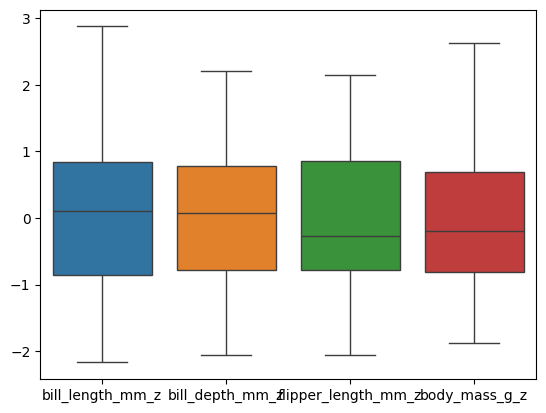

In [200]:
sns.boxplot(data= datos_estandarizados)

### Estadísticos descriptivos

In [201]:
v_cont = list(df_cont.columns)

describe_t = pd.DataFrame(df.describe()).T

estadisticos = describe_t.join(pd.DataFrame({
    'Varianza': df[v_cont].var(),
    'Coeficiente de Variación': (df[v_cont].std() / df[v_cont].mean())
}))

display(estadisticos)

,count,mean,std,min,25%,50%,75%,max,Varianza,Coeficiente de Variación
bill_length_mm,342.0,43.921930,5.459584,32.1,39.225,44.45,48.5,59.6,29.807054,0.124302
bill_depth_mm,342.0,17.151170,1.974793,13.1,15.600,17.30,18.7,21.5,3.899808,0.115140
flipper_length_mm,342.0,200.915205,14.061714,172.0,190.000,197.00,213.0,231.0,197.731792,0.069988
body_mass_g,342.0,4201.754386,801.954536,2700.0,3550.000,4050.00,4750.0,6300.0,643131.077327,0.190862


In [202]:
# Análisis de valores categóricos

df_cate.value_counts()

species    island     sex   
Gentoo     Biscoe     Male      65
                      Female    58
Chinstrap  Dream      Female    34
                      Male      34
Adelie     Dream      Male      29
                      Female    27
           Torgersen  Male      27
                      Female    24
           Biscoe     Female    22
                      Male      22
Name: count, dtype: int64

In [203]:
df_cate['species'].value_counts()

species
Adelie       151
Gentoo       123
Chinstrap     68
Name: count, dtype: int64

In [204]:
df_cate['sex'].value_counts()

sex
Male      177
Female    165
Name: count, dtype: int64

In [205]:
df_cate['island'].value_counts()

island
Biscoe       167
Dream        124
Torgersen     51
Name: count, dtype: int64

### 1. MATRIZ DE CORRELACIONES

In [335]:
R = df_cont.corr()
display(R)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.000000,-0.235053,0.656181,0.595110
bill_depth_mm,-0.235053,1.000000,-0.583851,-0.471916
flipper_length_mm,0.656181,-0.583851,1.000000,0.871202
body_mass_g,0.595110,-0.471916,0.871202,1.000000


<Axes: >

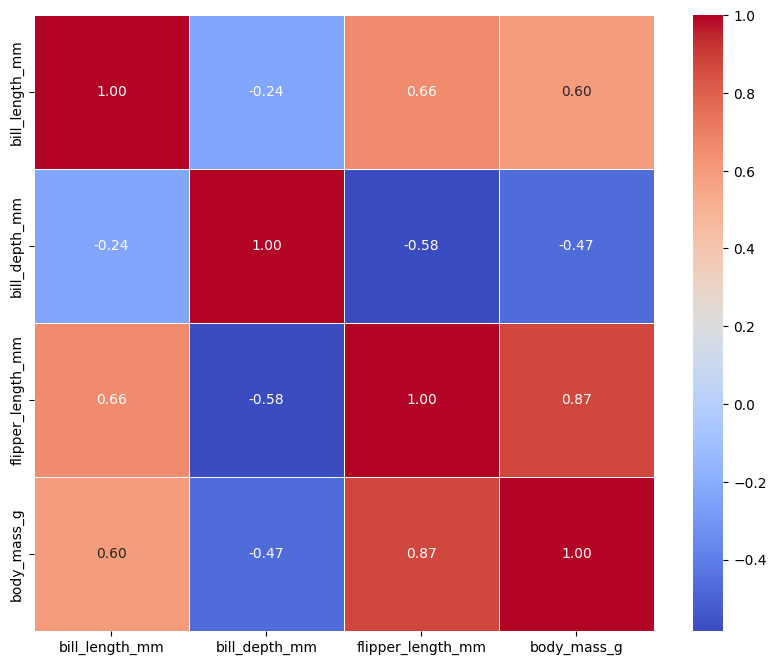

In [336]:
plt.figure(figsize=(10, 8))
sns.heatmap(R, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5) # R = df_cont.corr()

<Axes: xlabel='bill_length_mm', ylabel='bill_depth_mm'>

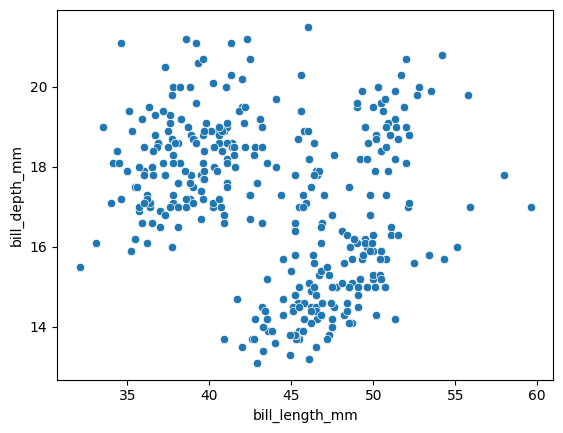

In [337]:
# Ejemplo de baja correlación (negativa)
sns.scatterplot(data = df, x= df['bill_length_mm'], y= df['bill_depth_mm'])


<Axes: xlabel='flipper_length_mm', ylabel='bill_depth_mm'>

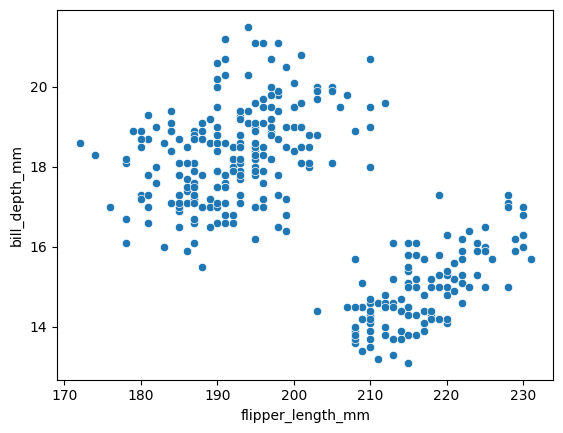

In [338]:
# Ejemplo de alta correlación negativa
sns.scatterplot(data = df, x=df['flipper_length_mm'], y= df['bill_depth_mm'])

<Axes: xlabel='flipper_length_mm', ylabel='body_mass_g'>

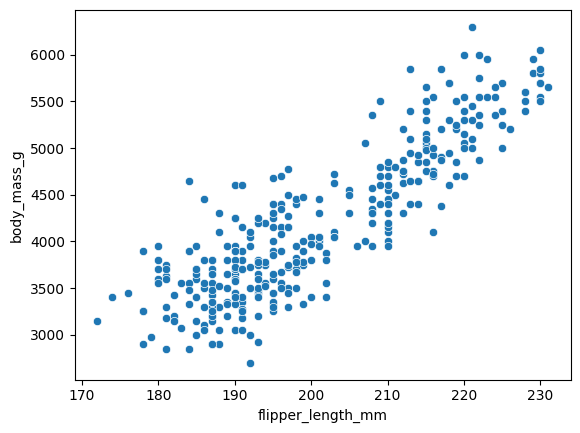

In [339]:
# Ejemplo de alta correlación positiva
sns.scatterplot(data = df, x=df['flipper_length_mm'], y= df['body_mass_g'])

In [340]:
# La alta correlación entre "body_mass_g" y "flipper_lenght_mm" nos permite considerar que cuanto más pese un pinguino, más largas esperamos que sean sus alas.
# La correlación entre la longitud y la altura (profundidad del perfil de pico) de los pingüinos es negativa, aunque no esté especialmente marcada.
# También, si nos fijamos en las correlaciones con "body_mass_g", podemos distinguir dos tipos de pingüino: aquellos más pesados, con un pico más largo y menos alto (baja profundidad del perfil de pico); y aquellos poco pesados, con un perfil de pico menos alargado y más alto.
# A su vez, los pinguinos con el ala más larga, pesan más y tienen el pico más largo pero bajo que los pingüinos con el ala más corta, menos pesados y con el pico más alto y corto.


# La correlación negativa entre la longitud de las alas y la altura del pico nos permite trazar la distinción entre dos grupos de pingüinos, hecho que podemos apreciar en el gráfico de dispersión entre ambas variables.

### 2. ANÁLISIS DE COMPONENTES PRINCIPALES (PCA): Selección de componentes principales.

In [212]:
# Es importante apuntar que en ausencia de correlaciones nuestro ACP arrojaría 
# resultados irrelevantes, ya que su funcionamiento depende de estas.

pca = PCA(n_components=4)   # Elegimos 4 máximo porque es el número de variables continuas del dataset original.

fit = pca.fit(datos_estandarizados)

autovalores = fit.explained_variance_

var_explicada = fit.explained_variance_ratio_*100

# Varianza explicada acumulada a medida que se agregan cada componente principal.
var_acumulada = np.cumsum(var_explicada)

# DataFrame de pandas con los datos anteriores e índice.
data = {'Autovalores': autovalores, 'Variabilidad Explicada': var_explicada, 'Variabilidad Acumulada': var_acumulada}
tabla = pd.DataFrame(data, index=['Componente {}'.format(i) for i in range(1, fit.n_components_+1)]) 

print(tabla)

              Autovalores  Variabilidad Explicada  Variabilidad Acumulada
Componente 1     2.761831               68.843878               68.843878
Componente 2     0.774782               19.312919               88.156797
Componente 3     0.366307                9.130898               97.287695
Componente 4     0.108810                2.712305              100.000000


Como vemos, las componentes se ordenan por valor del autovalor, que es la variabilidad explicada por cada componente, la primera componente es la que mayor variabilidad es capaz de explicar, mientras que la última es la que menos.

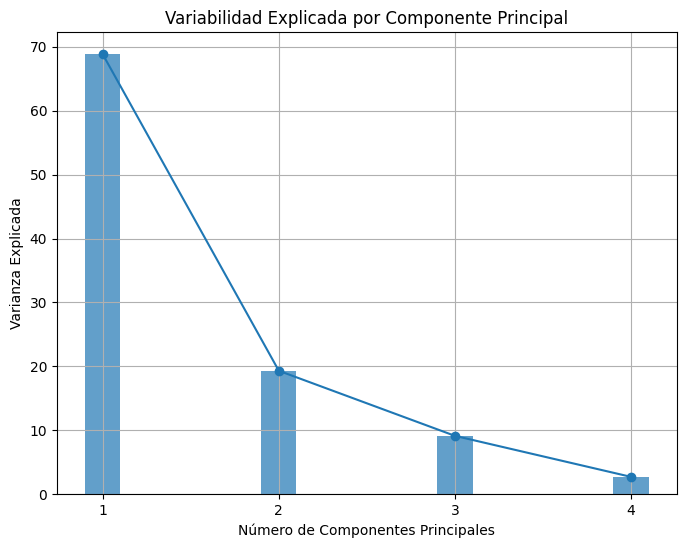

In [213]:
plot_varianza_explicada(var_explicada, fit.n_components_)

In [214]:
# El método del codo indica que debemos elegir 1 componente, ya que la varianza explicada cae con una pendiente 
# mucho más notable que para los sucesivos componentes.
#   Sin embargo, a fin de recoger mayor variabilidad (información), elegiremos 2 componentes.

### 3. ANÁLISIS DE COMPONENTES PRINCIPALES (PCA): Análisis con 2 componentes principales


#### Elegimos el número de componentes principales de nuestro análisis:

In [215]:
# Realizamos de nuevo el análisis de componentes principales.


# Análisis PCA
pca1 = PCA(n_components=2)
fit1 = pca1.fit(datos_estandarizados)


# Obtener los autovalores asociados a cada componente principal.
autovalores1 = fit1.explained_variance_


# Obtener los autovectores asociados a cada componente principal y transponerlos.
autovectores1 = pd.DataFrame(pca1.components_.T, 
                            columns = ['Autovector {}'.format(i) for i in range(1, fit1.n_components_+1)],
                            index = ['{}_z'.format(variable) for variable in variables])


# Calculamos las dos primeras componentes principales
resultados_pca1 = pd.DataFrame(fit1.transform(datos_estandarizados), 
                              columns=['Componente {}'.format(i) for i in range(1, fit1.n_components_+1)],
                              index=datos_estandarizados.index)


# Añadimos las componentes principales a la base de datos estandarizada.
datos_z_cp1 = pd.concat([datos_estandarizados, resultados_pca1], axis=1)


# Cálculo de las correlaciones entre las variables originales y las componentes seleccionadas.

# Guardamos el nombre de las variables del archivo conjunto (variables y componentes).
variables_cp1 = datos_z_cp1.columns
# Calculamos las correlaciones y seleccionamos las que nos interesan (variables contra componentes).
correlacion1 = pd.DataFrame(np.corrcoef(datos_estandarizados.T, resultados_pca1.T), 
                           index = variables_cp1, columns = variables_cp1)

n_variables1 = fit1.n_features_in_

# 3.a)
correlaciones_datos_con_cp1 = correlacion1.iloc[:fit1.n_features_in_, fit1.n_features_in_:]
print("Correlación entre componentes y variables:",
      "\n", 
      correlaciones_datos_con_cp1)
print("")
cos2 = correlaciones_datos_con_cp1 **2
print("Cosenos al cuadrado:",
      "\n", 
      cos2)

Correlación entre componentes y variables: 
                      Componente 1  Componente 2
bill_length_mm_z         0.755463      0.524748
bill_depth_mm_z         -0.664333      0.701180
flipper_length_mm_z      0.955862      0.002006
body_mass_g_z            0.909957      0.074149

Cosenos al cuadrado: 
                      Componente 1  Componente 2
bill_length_mm_z         0.570724      0.275361
bill_depth_mm_z          0.441338      0.491654
flipper_length_mm_z      0.913672      0.000004
body_mass_g_z            0.828021      0.005498


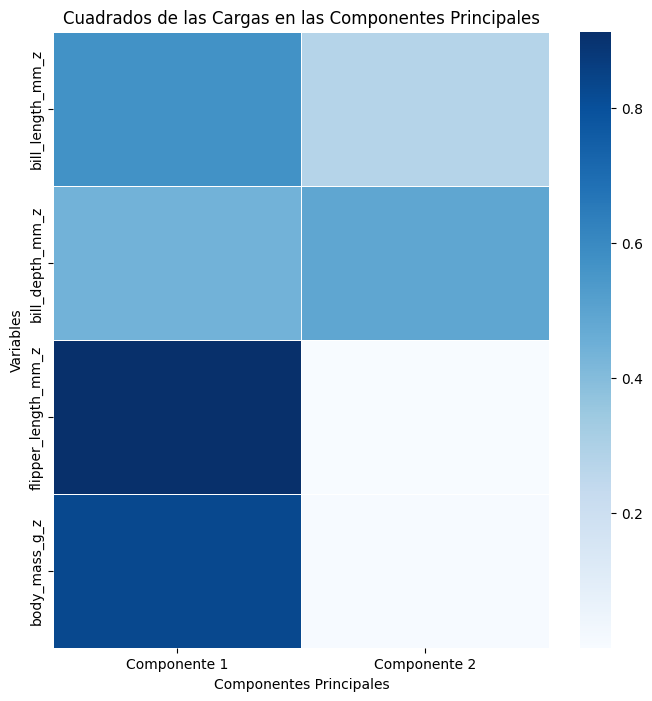

In [216]:
# Podemos visualizar la relación entre componentes y variables con:

plot_cos2_heatmap(cos2)

# Los cosenos al cuadrado expresan la proporción de la varianza de cada variable original que se explica mediante 
# cada componente principal.

Correlaciones entre Variables y Componentes Principales.
[AVISO] Se ignoró un ValueError durante el gráfico: Unable to determine Axes to steal space for Colorbar. Either provide the *cax* argument to use as the Axes for the Colorbar, provide the *ax* argument to steal space from it, or add *mappable* to an Axes.


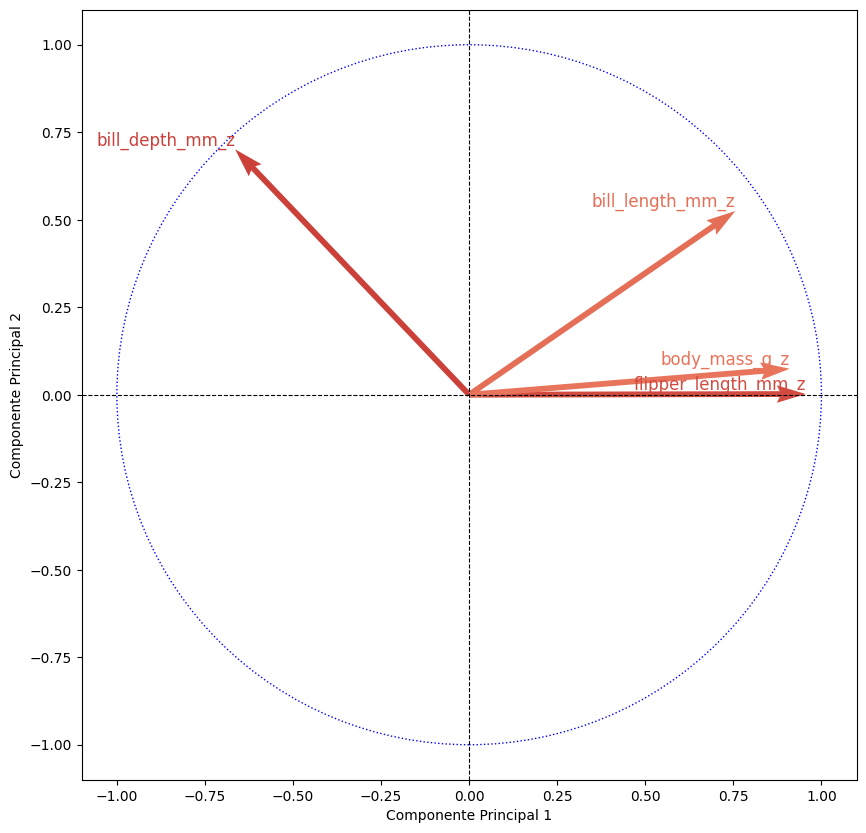

In [349]:
print("Correlaciones entre Variables y Componentes Principales.")

try:
    plot_corr_cos(fit1.n_components, correlaciones_datos_con_cp1)
except ValueError as e:
    print(f"[AVISO] Se ignoró un ValueError durante el gráfico: {e}")


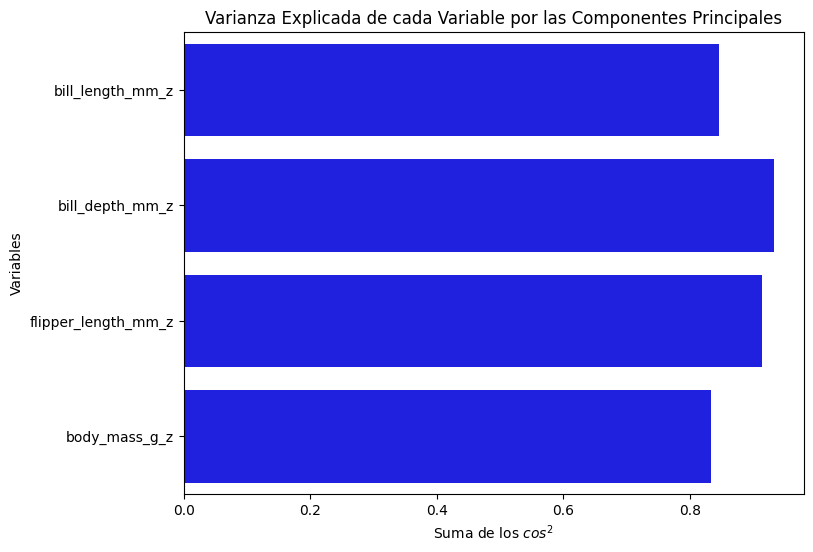

In [218]:
plot_cos2_bars(cos2)

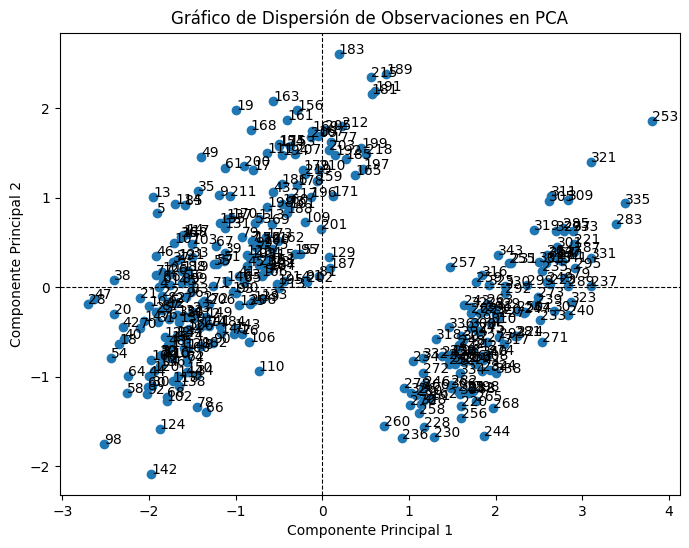

In [219]:
# 3.B)

plot_pca_scatter(pca, datos_estandarizados, fit1.n_components)

In [220]:
df_sup = pd.concat([datos_estandarizados, df['species']], axis=1)
df_sup.head()

resultados_pca1_sup = resultados_pca1.to_numpy()

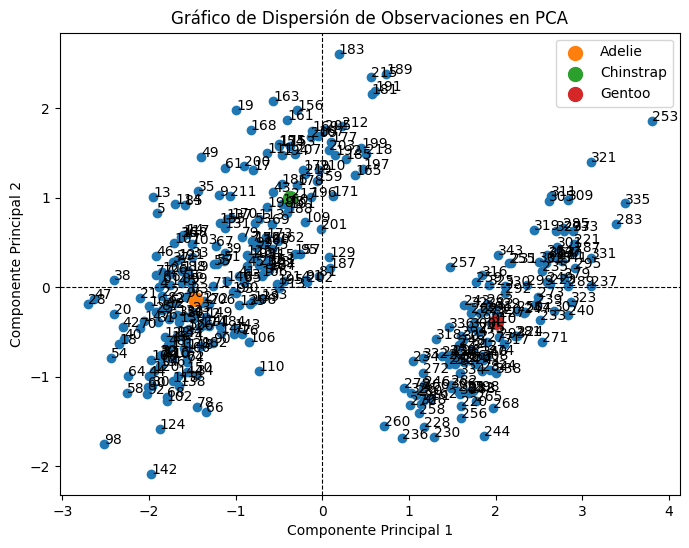

In [221]:
# Gráfico de dispersión PCA con los centróides de la variables categórica 'species'.

plot_pca_scatter_with_categories(df_sup, resultados_pca1_sup, fit1.n_components, 'species')

In [222]:
# 3.C) Un índice que podemos crear sería la media de las multiplicaciones de los valores estandarizados de las variables por 
# los autovectores asociados al primer componente principal (relacionado con peso y tamaño del ala).

autovectores = pca1.components_.T
cp1_coef = autovectores[:, 0]  # Primera columna: coeficientes de PC1

indice = datos_estandarizados.values @ cp1_coef


datos_indice = df_sup.copy()  # Datos estandarizados
datos_indice["indice"] = indice

# Valor promedio del índice por especie
indice_especie = datos_indice.groupby("species")["indice"].mean()
print(indice_especie)

species
Adelie      -1.463897
Chinstrap   -0.377341
Gentoo       2.005753
Name: indice, dtype: float64


### 4-AGRUPAMIENTO JERÁRQUICO.                                                       

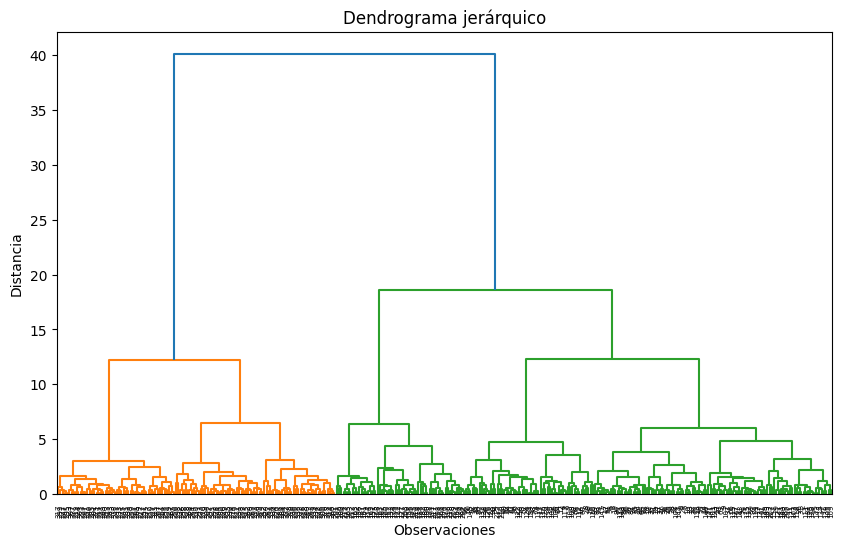

In [ ]:
from scipy.spatial.distance import pdist
import scipy.cluster.hierarchy as sch

# Estandarizamos los datos
df_std = pd.DataFrame(StandardScaler().fit_transform(df_cont), columns=df_cont.columns)

# Calculo de la matriz de distancias
dist_condensada = pdist(df_std, metric='euclidean')

# Creación del árbol jerárquico
linkage_matrix = sch.linkage(dist_condensada, method='ward')

# Crear dendrograma
plt.figure(figsize=(10, 6))
dendrogram = sch.dendrogram(linkage_matrix, labels=df_std.index)
plt.title("Dendrograma jerárquico")
plt.xlabel("Observaciones")
plt.ylabel("Distancia")
plt.show()


In [ ]:
# Podríamos cortar en 15 y tener 3 cluster o cortar en 10 y tener 5 clusters. Nos quedaremos con los 3 clusters ya que, teniendo en cuenta 
# el gran número de observaciones, tal vez nos interese captar diferencias algo menos específicas para no perder la imagen del grupo. 

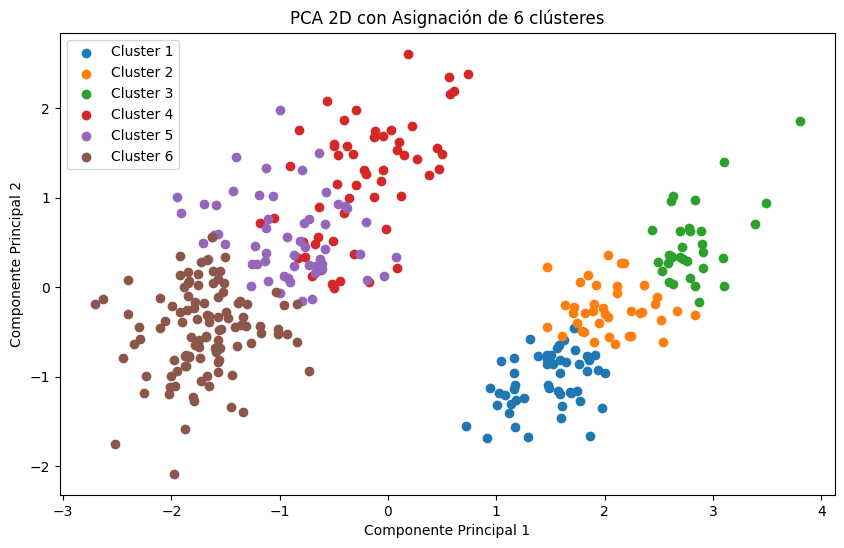

In [ ]:
from scipy.cluster.hierarchy import fcluster

num_clusters = 6
cluster_assignments = fcluster(linkage_matrix , num_clusters , criterion ='maxclust')

resultados_pca1['Cluster'] = cluster_assignments

plt.figure(figsize=(10, 6))

for cluster in np.unique(cluster_assignments):
    plt.scatter(
        resultados_pca1.loc[cluster_assignments == cluster, 'Componente 1'],
        resultados_pca1.loc[cluster_assignments == cluster, 'Componente 2'],
        label=f'Cluster {cluster}'
    )

plt.title(f"PCA 2D con Asignación de {num_clusters} clústeres")
plt.xlabel("Componente Principal 1")
plt.ylabel("Componente Principal 2")
plt.legend()
plt.grid(False)
plt.show()


### 5- AGRUPAMIENTO K-MEDIAS.                                                            

In [ ]:
# Versión modificada de plot_pca_clusters para enseñar los clústeres

def plot_pca_scatter_clusters(pca, datos_estandarizados, n_components, cluster_labels):
    """
    Genera gráficos de dispersión de observaciones en pares de componentes principales seleccionados,
    coloreando según los clusters.

    Args:
        pca (PCA): Objeto PCA previamente ajustado.
        datos_estandarizados (pd.DataFrame): DataFrame de datos estandarizados.
        n_components (int): Número de componentes principales seleccionadas.
        cluster_labels (array-like): Etiquetas de cluster para cada observación.
    """
    # Transformar los datos a componentes principales
    componentes_principales = pca.transform(datos_estandarizados)

    for i in range(n_components):
        for j in range(i + 1, n_components):
            plt.figure(figsize=(8, 6))
            scatter = plt.scatter(componentes_principales[:, i], componentes_principales[:, j],
                                  c=cluster_labels, cmap='viridis', s=50)

            # Añadir etiquetas a las observaciones
            etiquetas = list(datos_estandarizados.index)
            for k, label in enumerate(etiquetas):
                plt.annotate(label, (componentes_principales[k, i], componentes_principales[k, j]),
                             fontsize=8, alpha=0.7)

            plt.axhline(0, color='black', linestyle='--', linewidth=0.8)
            plt.axvline(0, color='black', linestyle='--', linewidth=0.8)

            plt.xlabel(f'Componente Principal {i + 1}')
            plt.ylabel(f'Componente Principal {j + 1}')
            plt.title(f'PCA-Kmedias ({kmeans.n_clusters} clústeres)')
            plt.grid(False)
            plt.show()


In [ ]:
from sklearn.cluster import KMeans

k = 4
kmeans = KMeans( n_clusters = k, random_state =0)
kmeans.fit(df_std)
kmeans_cluster_labels = kmeans.labels_

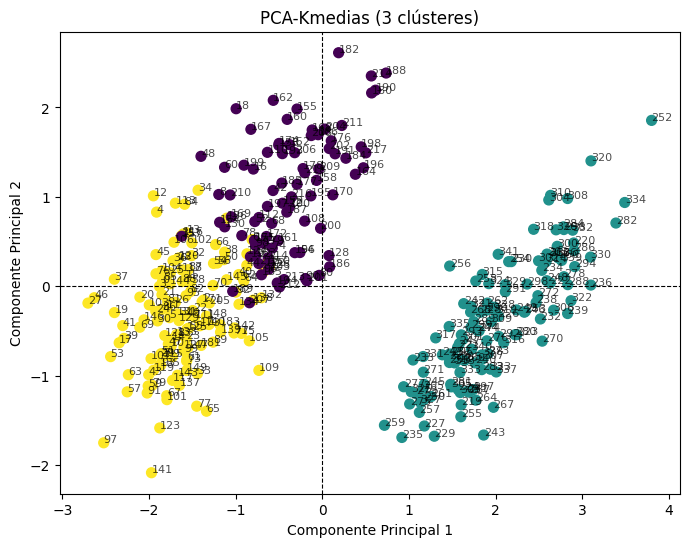

In [ ]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Estandaricion
df_std = pd.DataFrame(StandardScaler().fit_transform(df_cont), columns=df_cont.columns)

# Ajustar PCA
pca = PCA(n_components=2)
pca.fit(df_std)

# Ajustar KMeans
kmeans = KMeans(n_clusters=3, random_state=0)
kmeans.fit(df_std)

# Visualización
plot_pca_scatter_clusters(pca, df_std, n_components=2, cluster_labels=kmeans.labels_)

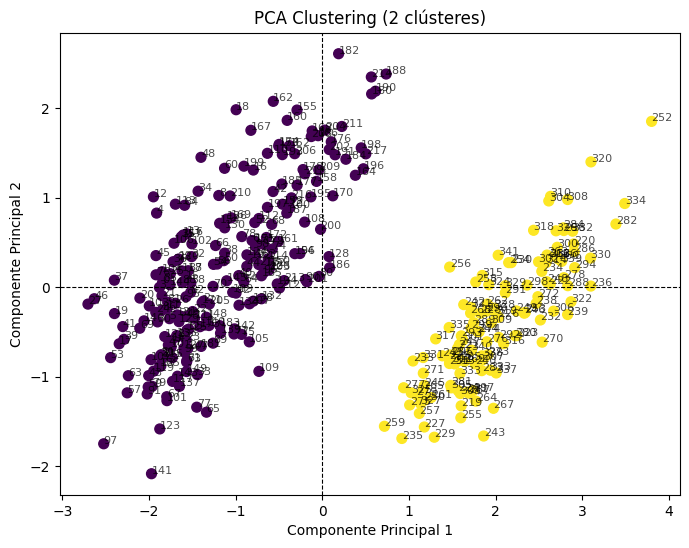

In [252]:
kmeans = KMeans(n_clusters=2, random_state=0)
kmeans.fit(df_std)

# Visualizar
plot_pca_scatter_clusters(pca, df_std, n_components=2, cluster_labels=kmeans.labels_)

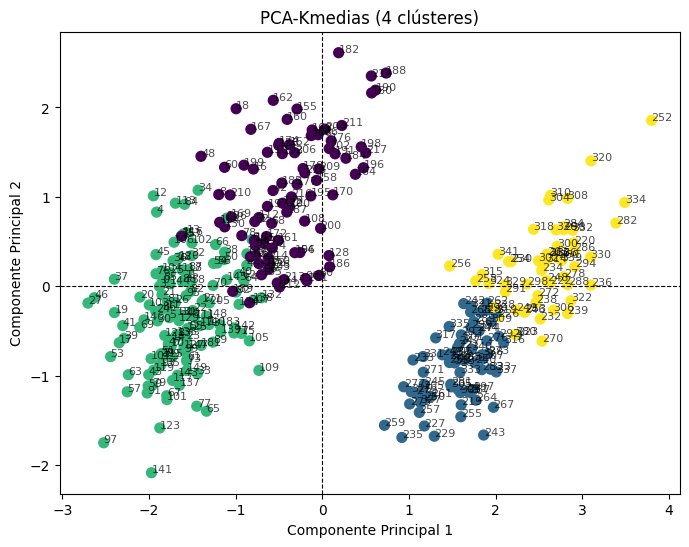

In [255]:
kmeans = KMeans(n_clusters=4, random_state=0)
kmeans.fit(df_std)

# Visualizar
plot_pca_scatter_clusters(pca, df_std, n_components=2, cluster_labels=kmeans.labels_)

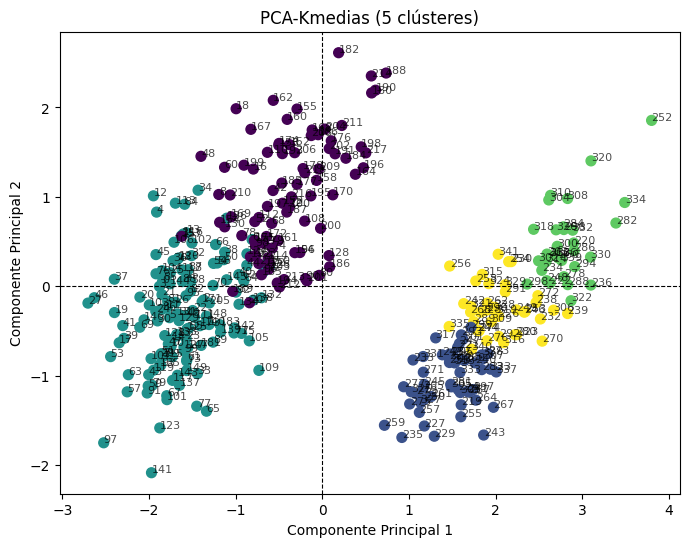

In [258]:
kmeans = KMeans(n_clusters=5, random_state=0)
kmeans.fit(df_std)

# Visualizar
plot_pca_scatter_clusters(pca, df_std, n_components=2, cluster_labels=kmeans.labels_)

<Figure size 800x600 with 0 Axes>

<Figure size 800x600 with 0 Axes>

<Figure size 800x600 with 0 Axes>

<Figure size 800x600 with 0 Axes>

<Figure size 800x600 with 0 Axes>

<Figure size 800x600 with 0 Axes>

<Figure size 800x600 with 0 Axes>

<Figure size 800x600 with 0 Axes>

<Figure size 800x600 with 0 Axes>

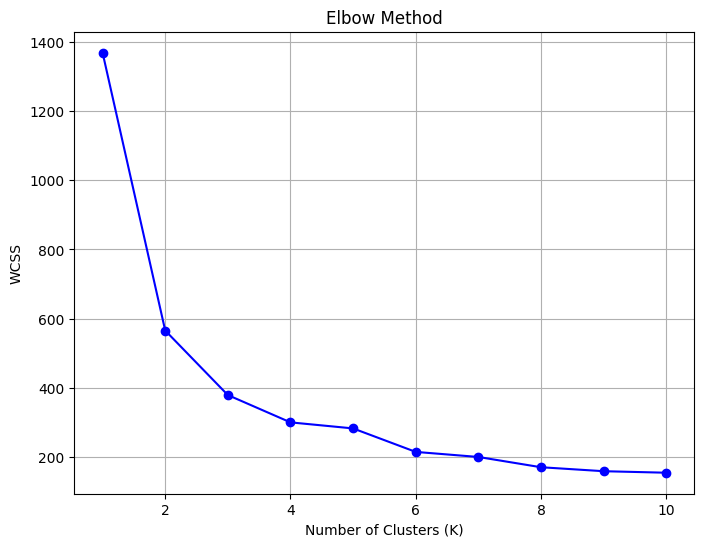

In [ ]:
wcss = []
for k in range (1, 11):
    kmeans = KMeans(n_clusters =k, random_state =0)
    kmeans.fit(df_std)
    wcss.append(kmeans.inertia_) 
    
    plt.figure( figsize =(8 , 6))
plt.plot(range (1, 11) , wcss , marker ='o', linestyle ='-', color ='b')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.grid(True )
plt.show()

### 6-VALIDACIÓN DEL AGRUPAMIENTO.                                               

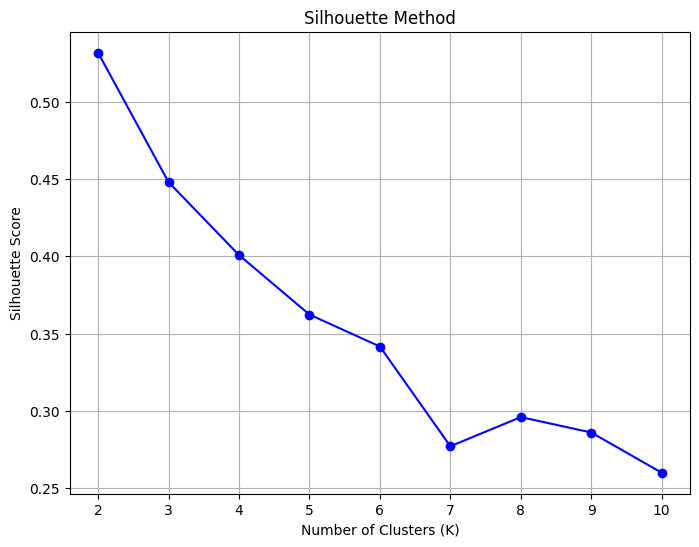

In [ ]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=0)
    kmeans.fit(df_std)
    labels = kmeans.labels_
    silhouette_avg = silhouette_score(df_std, labels)
    silhouette_scores.append(silhouette_avg)

plt.figure(figsize=(8, 6))
plt.plot(range(2, 11), silhouette_scores, marker='o', linestyle='-', color='b')
plt.title('Silhouette Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.grid(True)
plt.show()

In [ ]:
# Nos indica que debemos escoger 2 o 3 clusters.

C:\Users\ppabl\AppData\Local\Temp\ipykernel_8868\2909573468.py:18: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  color = plt.cm.get_cmap("Spectral")(float(i) / cluster_n)


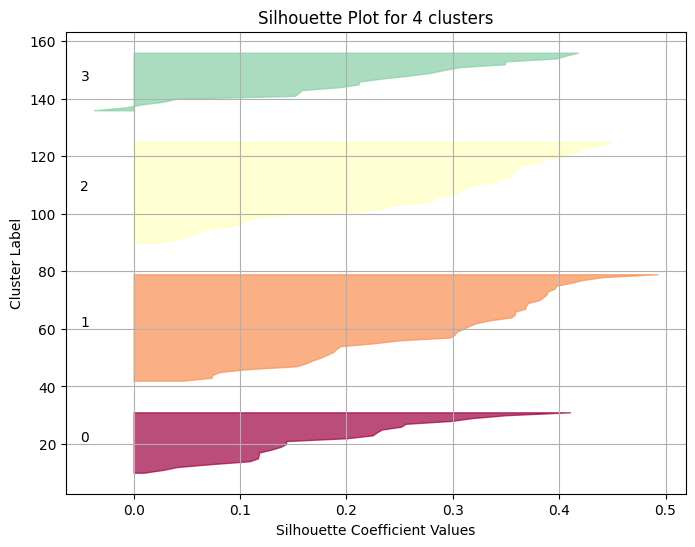

In [ ]:
from sklearn.metrics import silhouette_samples

silhouette_values = silhouette_samples(df_std, labels)

plt.figure(figsize=(8, 6))
y_lower = 10
cluster_n= 4

for i in range(cluster_n):
    ith_cluster_silhouette_values = silhouette_values[labels == i]
    ith_cluster_silhouette_values.sort()  # Ordena los valores
    
    size_cluster_i = ith_cluster_silhouette_values.shape[0]
    y_upper = y_lower + size_cluster_i

    color = plt.cm.get_cmap("Spectral")(float(i) / cluster_n)

    plt.fill_betweenx(
        np.arange(y_lower, y_upper),
        0,
        ith_cluster_silhouette_values,
        facecolor=color,
        edgecolor=color,
        alpha=0.7
    )

    plt.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))
    
    y_lower = y_upper + 10  

plt.title(f"Silhouette Plot for {cluster_n} clusters")
plt.xlabel("Silhouette Coefficient Values")
plt.ylabel("Cluster Label")
plt.grid(True)
plt.show()

### 7. MÉTODO JERÁRQUICO VS K-MEDIAS: Comparativa entre análisis.

In [276]:
grupo, conteo= np.unique(kmeans.labels_, return_counts=True)

print("K-medias:",
      "\n",
      "Frecuencia de datos en cada agrupación:",
      "\n",
      dict(zip(grupo, conteo)))

resultados_pca1['Cluster']

print("")
grupo, conteo= np.unique(resultados_pca1['Cluster'], return_counts=True)

print("Agrupación jerárquica:",
      "\n",
      "Frecuencia de datos en cada agrupación:",
      "\n",
      dict(zip(grupo, conteo)))

K-medias: 
 Frecuencia de datos en cada agrupación: 
 {0: 86, 1: 123, 2: 133}

Agrupación jerárquica: 
 Frecuencia de datos en cada agrupación: 
 {1: 123, 2: 57, 3: 162}


In [ ]:
# Gentoo es el grupo clasificado con 123 observaciones.
# El grupo con menos observaciones es Chinstrap, el grupo con más observaciones es Adelie.

# Vemos como la agrupación jerárquica tiende a acoger más Adelie de los que realmente hay (162 de 151 reales).

Comparación entre géneros de Gentoo

In [320]:
df_contgm = df[(df['species'] == 'Gentoo') & (df['sex'] == 'Male')].drop(['island', 'species'], axis=1)

describe_t = pd.DataFrame(df_contgm.describe()).T

estadisticos = describe_t.join(pd.DataFrame({
    'Varianza': df[v_cont].var(),
    'Coeficiente de Variación': (df[v_cont].std() / df[v_cont].mean())
}))

display(estadisticos)

,count,mean,std,min,25%,50%,75%,max,Varianza,Coeficiente de Variación
bill_length_mm,65.0,49.236923,2.810058,44.4,47.3,49.4,50.5,59.6,29.807054,0.124302
bill_depth_mm,65.0,15.646154,0.790980,13.8,15.1,15.7,16.1,17.3,3.899808,0.115140
flipper_length_mm,65.0,221.184615,5.675860,208.0,216.0,221.0,225.0,231.0,197.731792,0.069988
body_mass_g,65.0,5429.615385,380.169892,4100.0,5250.0,5500.0,5700.0,6300.0,643131.077327,0.190862


In [321]:
df_contgf = df[(df['species'] == 'Gentoo') & (df['sex'] == 'Female')].drop(['island', 'species'], axis=1)

describe_t = pd.DataFrame(df_contgf.describe()).T

estadisticos = describe_t.join(pd.DataFrame({
    'Varianza': df_contgf[v_cont].var(),
    'Coeficiente de Variación': (df_contgf[v_cont].std() / df[v_cont].mean())
}))

display(estadisticos)

,count,mean,std,min,25%,50%,75%,max,Varianza,Coeficiente de Variación
bill_length_mm,58.0,45.563793,2.051247,40.9,43.85,45.50,46.875,50.5,4.207613,0.046702
bill_depth_mm,58.0,14.237931,0.540249,13.1,13.80,14.25,14.600,15.5,0.291869,0.031499
flipper_length_mm,58.0,212.706897,3.897856,203.0,210.00,212.00,215.000,222.0,15.193285,0.019401
body_mass_g,58.0,4679.741379,281.578294,3950.0,4462.50,4700.00,4875.000,5200.0,79286.335451,0.067014
